# Практикалық жұмыс №7
## Тақырыбы: Басты компоненттер әдісі (Principal Component Analysis – PCA) негізінде деректердің өлшемділігін азайту
**Оқу бағдарламасы:** 6B06106 – Computer Science  
**Орындаған:** [Имя удалено по соображениям конфиденциальности]  
**Тексерген:** аға оқытушы [Имя удалено по соображениям конфиденциальности]  
**Вариант:** 14 (нұсқа №4: Wine Dataset деректері негізінде PCA әдісін зерттеу)

### 1. Қажетті кітапханаларды импорттау және деректерді жүктеу

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Визуализация стилі
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Деректерді жүктеу
df = pd.read_csv('data.csv')
print("Деректер өлшемі:", df.shape)
df.head()

Деректер өлшемі: (250, 21)


,sample_id,sommelier_name,sommelier_gender,sommelier_birth_year,vineyard_region,vintage_year,wine_category,alcohol,malic_acid,ash,...,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,wine_class
0,WN_2026_1001,Қасымова Аружан,Әйел,1981,Шымкент маңы,2020,Ақ десертті,13.97,1.91,2.61,...,103.8,2.76,3.61,0.34,1.71,6.20,1.00,2.99,1169.0,0
1,WN_2026_1002,Кәрімов Мұрат,Ер,1979,Түркістан облысы (Сарыағаш),2018,Ақ десертті,11.25,0.74,2.06,...,99.8,1.77,1.08,0.54,1.49,3.15,0.78,2.52,538.0,1
2,WN_2026_1003,Әубәкірова Мәдина,Әйел,1984,Жамбыл облысы (Мерке),2022,Ақ десертті,12.54,3.74,2.33,...,92.7,2.35,0.78,0.32,1.49,4.58,0.70,1.27,477.0,2
3,WN_2026_1004,Жақыпов Нұрлан,Ер,1992,Жамбыл облысы (Мерке),2024,Қызыл классикалық құрғақ,12.39,2.68,2.29,...,89.4,1.46,1.57,0.30,2.26,3.41,0.71,2.95,459.0,1
4,WN_2026_1005,Кәрімов Айдос,Ер,1995,Түркістан облысы (Сарыағаш),2018,Қызыл таңдаулы,11.91,2.55,2.57,...,80.4,2.09,2.32,0.48,1.34,2.92,0.84,2.19,648.0,1


### 2. Химиялық белгілердің статистикалық сипаттамаларын зерттеу

In [2]:
feature_cols = [
    'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
    'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins',
    'color_intensity', 'hue', 'od280_od315', 'proline'
]
target_col = 'wine_class'

X = df[feature_cols]
y = df[target_col]

print("Белгілер саны:", len(feature_cols))
print("Бақылаулар саны:", len(X))
X.describe().round(2)

Белгілер саны: 13
Бақылаулар саны: 250


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,13.08,2.54,2.37,19.59,101.84,2.29,1.96,0.38,1.58,5.30,0.94,2.55,770.44
std,0.81,1.09,0.26,3.12,12.92,0.61,1.03,0.12,0.55,2.52,0.22,0.70,305.84
min,11.09,0.74,1.46,11.20,70.00,0.98,0.34,0.13,0.40,1.30,0.48,1.27,278.00
25%,12.43,1.62,2.23,17.50,93.32,1.84,0.98,0.29,1.20,3.55,0.74,1.92,542.00
50%,13.16,2.42,2.42,19.30,100.55,2.29,2.20,0.36,1.58,4.93,0.98,2.72,686.00
75%,13.78,3.17,2.55,21.60,109.40,2.78,2.84,0.46,2.02,6.83,1.10,3.10,972.25
max,14.69,5.80,3.02,30.00,142.70,3.51,3.80,0.63,2.94,13.00,1.60,3.94,1680.00


### 3. Белгілерді стандарттау (StandardScaler)

In [3]:
# Белгілер әртүрлі масштабта болғандықтан PCA алдында стандарттау міндетті
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Стандартталған деректер матрицасы:", X_scaled.shape)
print("Орташа мәндер (0-ге жақын):", np.round(X_scaled.mean(axis=0), 3))
print("Дисперсиялар (1-ге тең):", np.round(X_scaled.var(axis=0), 3))

Стандартталған деректер матрицасы: (250, 13)
Орташа мәндер (0-ге жақын): [ 0. -0. -0. -0.  0.  0. -0.  0.  0.  0. -0.  0.  0.]
Дисперсиялар (1-ге тең): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4. Толық PCA (13 компонент) және дисперсия үлесін есептеу

In [4]:
pca_full = PCA(n_components=13, random_state=42)
pca_full.fit(X_scaled)

exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

df_var = pd.DataFrame({
    'Компонент': [f'PC{i+1}' for i in range(13)],
    'Түсіндірілетін дисперсия (%)': np.round(exp_var * 100, 2),
    'Кумулятивті дисперсия (%)': np.round(cum_var * 100, 2)
})
df_var

,Компонент,Түсіндірілетін дисперсия (%),Кумулятивті дисперсия (%)
0,PC1,36.76,36.76
1,PC2,16.92,53.68
2,PC3,8.17,61.85
3,PC4,6.46,68.31
4,PC5,5.86,74.17
5,PC6,5.11,79.28
6,PC7,4.81,84.09
7,PC8,3.80,87.89
8,PC9,3.28,91.17
9,PC10,2.75,93.92


### 5. Scree Plot (Дисперсия графигі)

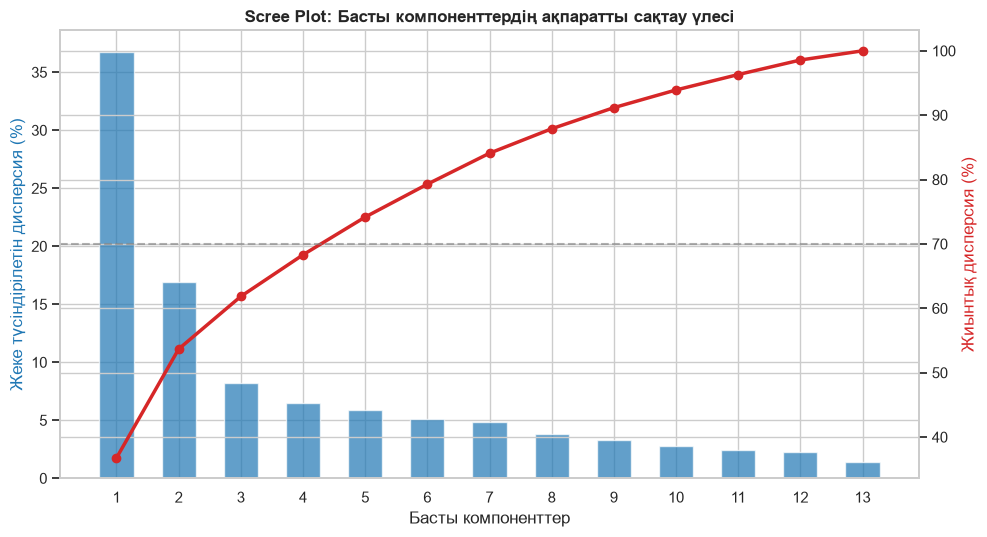

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5.5))

ax1.bar(range(1, 14), exp_var * 100, color='#1f77b4', alpha=0.7, width=0.55, label='Жеке дисперсия')
ax1.set_xlabel('Басты компоненттер')
ax1.set_ylabel('Жеке түсіндірілетін дисперсия (%)', color='#1f77b4')
ax1.set_xticks(range(1, 14))

ax2 = ax1.twinx()
ax2.plot(range(1, 14), cum_var * 100, color='#d62728', marker='o', linewidth=2.5, label='Кумулятивті дисперсия')
ax2.set_ylabel('Жиынтық дисперсия (%)', color='#d62728')
ax2.axhline(y=70, color='gray', linestyle='--', alpha=0.6, label='70% шегі')

plt.title('Scree Plot: Басты компоненттердің ақпаратты сақтау үлесі', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

### 6. PCA 2D түрлендіру (n_components=2) және визуализация

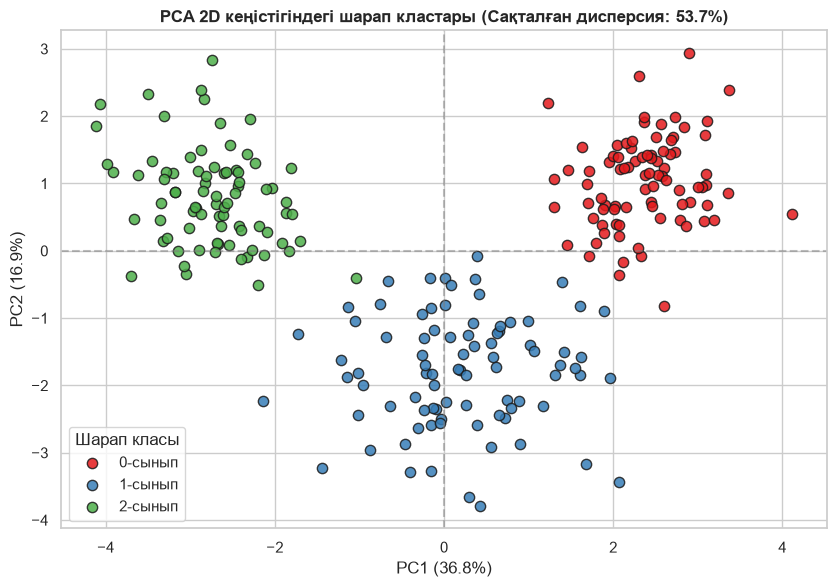

In [6]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

df_2d = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_2d['wine_class'] = y

plt.figure(figsize=(8.5, 6))
palette = ['#e41a1c', '#377eb8', '#4daf4a']
labels = ['0-сынып', '1-сынып', '2-сынып']
for c_idx in range(3):
    sub = df_2d[df_2d['wine_class'] == c_idx]
    plt.scatter(sub['PC1'], sub['PC2'], c=palette[c_idx], label=labels[c_idx], alpha=0.85, edgecolors='k', s=55)

plt.title(f'PCA 2D кеңістігіндегі шарап кластары (Сақталған дисперсия: {sum(pca_2d.explained_variance_ratio_)*100:.1f}%)', fontsize=12, fontweight='bold')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.legend(title='Шарап класы')
plt.tight_layout()
plt.show()

### 7. PCA 3D түрлендіру (n_components=3)

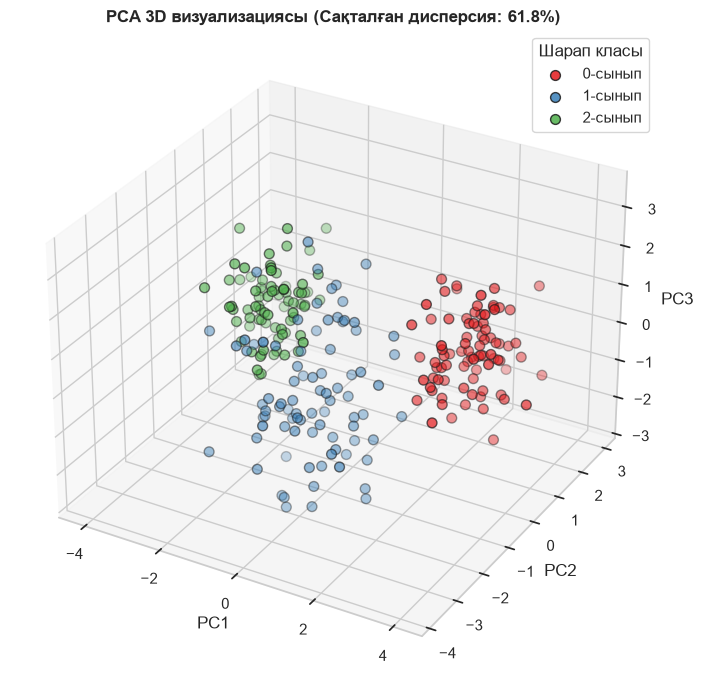

In [7]:
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
for c_idx in range(3):
    mask = (y == c_idx)
    ax.scatter(X_pca_3d[mask, 0], X_pca_3d[mask, 1], X_pca_3d[mask, 2],
               c=palette[c_idx], label=labels[c_idx], alpha=0.85, edgecolors='k', s=50)

ax.set_title(f'PCA 3D визуализациясы (Сақталған дисперсия: {sum(pca_3d.explained_variance_ratio_)*100:.1f}%)', fontsize=12, fontweight='bold')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.legend(title='Шарап класы')
plt.tight_layout()
plt.show()

### 8. Компоненттердің салмақтық үлестері (Loadings)

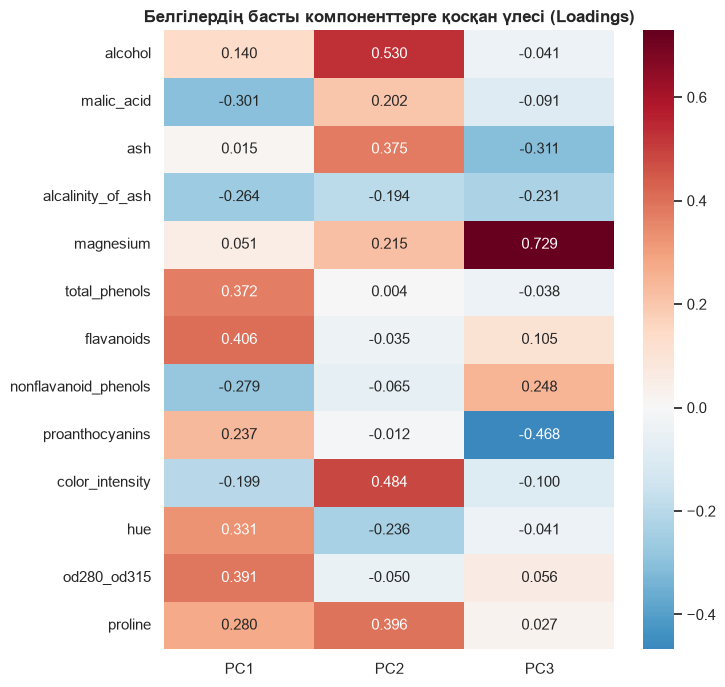

In [8]:
loadings = pd.DataFrame(
    pca_3d.components_.T,
    columns=['PC1', 'PC2', 'PC3'],
    index=feature_cols
)

plt.figure(figsize=(7.5, 7))
sns.heatmap(loadings, annot=True, fmt=".3f", cmap='RdBu_r', center=0)
plt.title('Белгілердің басты компоненттерге қосқан үлесі (Loadings)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 9. Өлшемділікті салыстыру қорытындысы

In [9]:
summary_df = pd.DataFrame({
    'Көрсеткіш': ['Бақылаулар саны', 'Белгілер саны', 'Өлшемділік', 'Ақпараттың сақталуы (дисперсия)', 'Визуализация мүмкіндігі'],
    'Бастапқы деректер': [len(df), len(feature_cols), '13 өлшем', '100%', 'Күрделі (көпөлшемді)'],
    'PCA (2 компонент)': [len(df), 2, '2 өлшем', f'{sum(pca_2d.explained_variance_ratio_)*100:.2f}%', '2D жазықтық'],
    'PCA (3 компонент)': [len(df), 3, '3 өлшем', f'{sum(pca_3d.explained_variance_ratio_)*100:.2f}%', '3D кеңістік']
})
summary_df

,Көрсеткіш,Бастапқы деректер,PCA (2 компонент),PCA (3 компонент)
0,Бақылаулар саны,250,250,250
1,Белгілер саны,13,2,3
2,Өлшемділік,13 өлшем,2 өлшем,3 өлшем
3,Ақпараттың сақталуы (дисперсия),100%,53.68%,61.85%
4,Визуализация мүмкіндігі,Күрделі (көпөлшемді),2D жазықтық,3D кеңістік
